<a href="https://colab.research.google.com/github/ftyhanifah/Analisis-Deret-Waktu/blob/main/Tugas_Kelompok_9_Minggu_ke_8_Penduga_Parameter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Kelompok 9 — Pendugaan Parameter ARIMA: Kuadrat Terkecil vs Kemungkinan Maksimum

**Kelompok 9**


1.   Nurqalbu Abd.Mutalip (M0501251021)
2.   Fatiya Hanifah (M0501251053)
3.   Muhammad Alief Nur Widiyanto (M0501261096)

## Tujuan dan rancangan
Membandingkan pendugaan parameter menggunakan Kuadrat Terkecil bersyarat (**LS/CSS**) dan Kemungkinan Maksimum (**MLE**) pada ARIMA(2,0,2) dan ARIMA(1,2,1).

| Komponen | Ketentuan |
|---|---|
| Panjang deret level | 500 pengamatan per model |
| Simulasi nomor 1 | Satu realisasi per model, seed 2570 |
| Simulasi nomor 2 | 30 realisasi per model, seed 12345–12374 |
| Parameter | Tetap selama seluruh ulangan |
| Inovasi | Saling bebas, berdistribusi normal N(0,1) |
| Burn-in | 300 pengamatan pada komponen ARMA |
| Konstanta | Tidak digunakan |
| Perbandingan | Data yang sama untuk CSS dan MLE pada tiap ulangan |
| Implementasi | `stats::arima(method="CSS")` dan `stats::arima(method="ML")` |

Seed 2570 digunakan sesuai ketentuan kelompok untuk nomor 1. Pada nomor 2 dipakai seed terpisah; setiap seed digunakan untuk satu ulangan pada masing-masing model. Kesimpulan dibuat per model, bukan dari perbandingan besar ragam antar-model.

In [1]:
# Persiapan satu kali setiap sesi Colab baru
import os, sys, shutil, subprocess, importlib.util
if shutil.which("R") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "--no-install-recommends", "r-base"], check=True)
os.environ["R_HOME"] = subprocess.check_output(["R", "RHOME"], text=True).strip()
if importlib.util.find_spec("rpy2") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rpy2"], check=True)

In [2]:
%load_ext rpy2.ipython
%R R.version.string

array(['R version 4.6.1 (2026-06-24)'], dtype='<U28')

## 1. Model dan parameter sebenarnya
Konvensi tanda mengikuti R: $\phi(B)=1-\phi_1B-\phi_2B^2$ dan $\theta(B)=1+\theta_1B+\theta_2B^2$.

**ARIMA(2,0,2)**
$$Y_t=0.6Y_{t-1}-0.3Y_{t-2}+\varepsilon_t+0.5\varepsilon_{t-1}+0.3\varepsilon_{t-2}.$$

**ARIMA(1,2,1)**, dengan $W_t=\Delta^2Y_t=Y_t-2Y_{t-1}+Y_{t-2}$:
$$W_t=0.7W_{t-1}+\varepsilon_t-0.4\varepsilon_{t-1}.$$

Pada model kedua, $\theta_1=-0.4$ dalam konvensi positif R. Deret level $Y_t$ tidak stasioner; syarat stasioneritas berlaku pada $W_t$.

### Pemeriksaan pertidaksamaan
| Komponen | Syarat | Substitusi | Hasil |
|---|---|---|---|
| AR(2) | $|\phi_2|<1$ | $0.3<1$ | Terpenuhi |
| AR(2) | $\phi_1+\phi_2<1$ | $0.3<1$ | Terpenuhi |
| AR(2) | $\phi_2-\phi_1<1$ | $-0.9<1$ | Terpenuhi |
| MA(2) | $|\theta_2|<1$ | $0.3<1$ | Terpenuhi |
| MA(2) | $\theta_1+\theta_2>-1$ | $0.8>-1$ | Terpenuhi |
| MA(2) | $\theta_2-\theta_1>-1$ | $-0.2>-1$ | Terpenuhi |
| AR(1) model kedua | $|\phi_1|<1$ | $0.7<1$ | Terpenuhi |
| MA(1) model kedua | $|\theta_1|<1$ | $0.4<1$ | Terpenuhi |

Bagian AR diperiksa untuk stasioneritas, sedangkan bagian MA diperiksa untuk invertibilitas. Sel berikut memverifikasi bahwa seluruh akar polinomial terkait berada di luar lingkaran satuan.

In [3]:
%%R
# Pengaturan simulasi: parameter tetap untuk seluruh ulangan.
N <- 500L
B <- 30L
SEED_NIM <- 2570L
BASE_SEED <- 12345L
out <- 'hasil_kelompok9_final'
dir.create(out, showWarnings=FALSE)
RNGkind('Mersenne-Twister','Inversion','Rejection')
models <- list(
  'ARIMA(2,0,2)'=list(order=c(2,0,2), ar=c(0.6,-0.3), ma=c(0.5,0.3)),
  'ARIMA(1,2,1)'=list(order=c(1,2,1), ar=0.7, ma=-0.4)
)
true_coef <- function(m) c(setNames(m$ar,paste0('phi',seq_along(m$ar))),
                         setNames(m$ma,paste0('theta',seq_along(m$ma))))
roots <- do.call(rbind,lapply(names(models),function(id) {
 m <- models[[id]]
 a <- Mod(polyroot(c(1,-m$ar))); b <- Mod(polyroot(c(1,m$ma)))
 stopifnot(all(a>1),all(b>1))
 data.frame(Model=id,Komponen=c(rep('AR',length(a)),rep('MA',length(b))),
            Modulus=c(a,b),Lulus=c(a,b)>1)
}))
print(roots,row.names=FALSE,digits=6)
cat('\nN =',N,'; ulangan =',B,'; inovasi N(0,1); burn-in = 300\n')

        Model Komponen Modulus Lulus
 ARIMA(2,0,2)       AR 1.82574  TRUE
 ARIMA(2,0,2)       AR 1.82574  TRUE
 ARIMA(2,0,2)       MA 1.82574  TRUE
 ARIMA(2,0,2)       MA 1.82574  TRUE
 ARIMA(1,2,1)       AR 1.42857  TRUE
 ARIMA(1,2,1)       MA 2.50000  TRUE

N = 500 ; ulangan = 30 ; inovasi N(0,1); burn-in = 300


**Interpretasi:** modulus akar AR dan MA model pertama masing-masing sekitar 1,825742. Model kedua memiliki modulus akar AR sekitar 1,428571 dan MA sebesar 2,5. Seluruhnya lebih besar dari satu. Akar unit yang berasal dari faktor pembedaan `(1−B)²` pada model kedua memang tidak dihilangkan dari deret level.

## 2. Fungsi simulasi dan pendugaan
CSS meminimumkan jumlah kuadrat inovasi bersyarat dengan penanganan nilai awal sesuai implementasi `stats::arima`. MLE memaksimumkan likelihood Gaussian melalui representasi ruang keadaan pada fungsi yang sama. Keduanya menggunakan model tanpa konstanta.

`arima.sim` menambahkan $d$ nilai awal saat integrasi. Karena itu digunakan `n=N-d`, sehingga panjang **deret level tepat 500**; setelah pembedaan dua kali, model kedua memiliki 498 pengamatan.

Setiap pendugaan diperiksa melalui kode konvergensi, koefisien yang berhingga, dan ragam inovasi positif. Jika percobaan awal gagal, batas iterasi dinaikkan pada data yang sama. Jika tetap gagal, proses dihentikan. Peringatan disimpan dalam audit dan tidak diabaikan. Tidak ada ulangan yang dibuang atau diganti untuk memperoleh hasil tertentu.

In [4]:
%%R
simulate <- function(m) {
 # arima.sim menambahkan d nilai awal integrasi: n=N-d memberi panjang level N.
 y <- as.numeric(stats::arima.sim(model=m,n=N-m$order[2],n.start=300,sd=1))
 stopifnot(length(y)==N,all(is.finite(y)))
 y
}
fit_checked <- function(y,m,method) {
 notes <- character()
 run <- function(maxit,init=NULL) {
  tryCatch(withCallingHandlers(
   stats::arima(y,order=m$order,include.mean=FALSE,method=method,
                init=init,optim.control=list(maxit=maxit)),
   warning=function(w) {notes <<- c(notes,conditionMessage(w));invokeRestart('muffleWarning')}
  ),error=function(e) e)
 }
 good <- function(f) !inherits(f,'error') && isTRUE(f$code==0) &&
    all(is.finite(coef(f))) && is.finite(f$sigma2) && f$sigma2>0
 f <- run(2000); attempts <- 1L
 if(!good(f)) {
  # Ulang optimisasi pada DATA YANG SAMA; tidak mengganti data atau seed.
  init <- if(!inherits(f,'error') && all(is.finite(coef(f)))) coef(f) else NULL
  f <- run(10000,init); attempts <- 2L
 }
 if(!good(f)) stop('Pendugaan belum konvergen: hentikan dan periksa data; jangan buang ulangan.')
 est <- setNames(as.numeric(coef(f)),names(true_coef(m)))
 list(est=est,code=f$code,attempts=attempts,warning=paste(unique(notes),collapse=' | '))
}
fit_pair <- function(y,m,id,b) {
 do.call(rbind,lapply(c('CSS','ML'),function(method) {
  f <- fit_checked(y,m,method)
  data.frame(Model=id,Ulangan=b,Metode=method,Parameter=names(f$est),
   Benar=as.numeric(true_coef(m)),Dugaan=as.numeric(f$est),
   Galat=as.numeric(f$est-true_coef(m)),Kode=f$code,Percobaan=f$attempts,
   Peringatan=f$warning,row.names=NULL)
 }))
}
cat('Fungsi simulasi dan pendugaan siap. CSS dan ML menggunakan stats::arima.\n')

Fungsi simulasi dan pendugaan siap. CSS dan ML menggunakan stats::arima.


## 3. Nomor 1 — satu ulangan dengan seed 2570
Seed 2570 dipasang sebelum pembangkitan setiap model. Data yang sama kemudian digunakan oleh CSS dan MLE. Galat pendugaan adalah estimasi dikurangi nilai parameter sebenarnya.

In [5]:
%%R
single_data <- list(); single_rows <- list()
for(id in names(models)) {
 # Seed yang sama dipasang untuk SATU realisasi setiap model, sesuai rancangan awal.
 set.seed(SEED_NIM)
 y <- simulate(models[[id]])
 single_data[[id]] <- y
 single_rows[[id]] <- fit_pair(y,models[[id]],id,1)
}
single <- do.call(rbind,single_rows); rownames(single) <- NULL
print(single[,c('Model','Metode','Parameter','Benar','Dugaan','Galat')],digits=6,row.names=FALSE)
write.table(single,file.path(out,'satu_ulangan.tsv'),sep='\t',row.names=FALSE)

        Model Metode Parameter Benar    Dugaan       Galat
 ARIMA(2,0,2)    CSS      phi1   0.6  0.627306  0.02730601
 ARIMA(2,0,2)    CSS      phi2  -0.3 -0.309453 -0.00945289
 ARIMA(2,0,2)    CSS    theta1   0.5  0.436770 -0.06323000
 ARIMA(2,0,2)    CSS    theta2   0.3  0.230843 -0.06915693
 ARIMA(2,0,2)     ML      phi1   0.6  0.614392  0.01439178
 ARIMA(2,0,2)     ML      phi2  -0.3 -0.302054 -0.00205419
 ARIMA(2,0,2)     ML    theta1   0.5  0.448461 -0.05153893
 ARIMA(2,0,2)     ML    theta2   0.3  0.236174 -0.06382609
 ARIMA(1,2,1)    CSS      phi1   0.7  0.688773 -0.01122742
 ARIMA(1,2,1)    CSS    theta1  -0.4 -0.436123 -0.03612278
 ARIMA(1,2,1)     ML      phi1   0.7  0.686078 -0.01392166
 ARIMA(1,2,1)     ML    theta1  -0.4 -0.431246 -0.03124617


### Interpretasi satu ulangan
Pada ARIMA(2,0,2), MLE menghasilkan galat absolut lebih kecil daripada CSS untuk seluruh parameter pada realisasi ini. Sebagai contoh, estimasi φ₁ adalah 0,627306 (CSS) dan 0,614392 (MLE), dengan nilai sebenarnya 0,6.

Pada ARIMA(1,2,1), CSS menghasilkan galat absolut lebih kecil untuk φ₁, sedangkan MLE lebih kecil untuk θ₁. Estimasi φ₁ masing-masing 0,688773 dan 0,686078; nilai sebenarnya 0,7. Estimasi θ₁ masing-masing −0,436123 dan −0,431246; nilai sebenarnya −0,4.

Hasil satu realisasi belum dapat digunakan untuk menentukan metode yang secara umum lebih baik. Bias dan ragam empiris dievaluasi melalui 30 ulangan pada nomor 2.

## 4. Visualisasi deret dan ACF/PACF
Grafik ACF/PACF merupakan pelengkap untuk melihat ketergantungan waktu; orde model telah ditetapkan oleh tugas.

In [6]:
%%R
png(file.path(out,'01_deret.png'),width=1600,height=1200,res=150)
par(mfrow=c(3,1),mar=c(4,4.5,3,1),mgp=c(2.5,0.8,0))
plot(single_data[[1]],type='l',col='#236A82',xlab='Waktu',ylab='Y(t)',
 main='ARIMA(2,0,2): deret stasioner (n = 500)');abline(h=0,lty=2,col='gray50')
plot(single_data[[2]],type='l',col='#B86B3D',xlab='Waktu',ylab='Y(t)',
 main='ARIMA(1,2,1): deret tidak stasioner (n = 500)')
plot(3:N,diff(single_data[[2]],differences=2),type='l',col='#236A82',xlab='Waktu',
 ylab='Selisih kedua',main='ARIMA(1,2,1): setelah pembedaan dua kali')
abline(h=0,lty=2,col='gray50');dev.off()
png(file.path(out,'02_acf_pacf.png'),width=1600,height=1000,res=150)
par(mfrow=c(2,2),mar=c(4,4,3,1))
for(id in names(models)) {
 d <- models[[id]]$order[2]
 w <- if(d>0) diff(single_data[[id]],differences=d) else single_data[[id]]
 stats::acf(w,lag.max=24,main=paste('ACF:',id,'d =',d))
 stats::pacf(w,lag.max=24,main=paste('PACF:',id,'d =',d))
}
dev.off()

png 
  2 


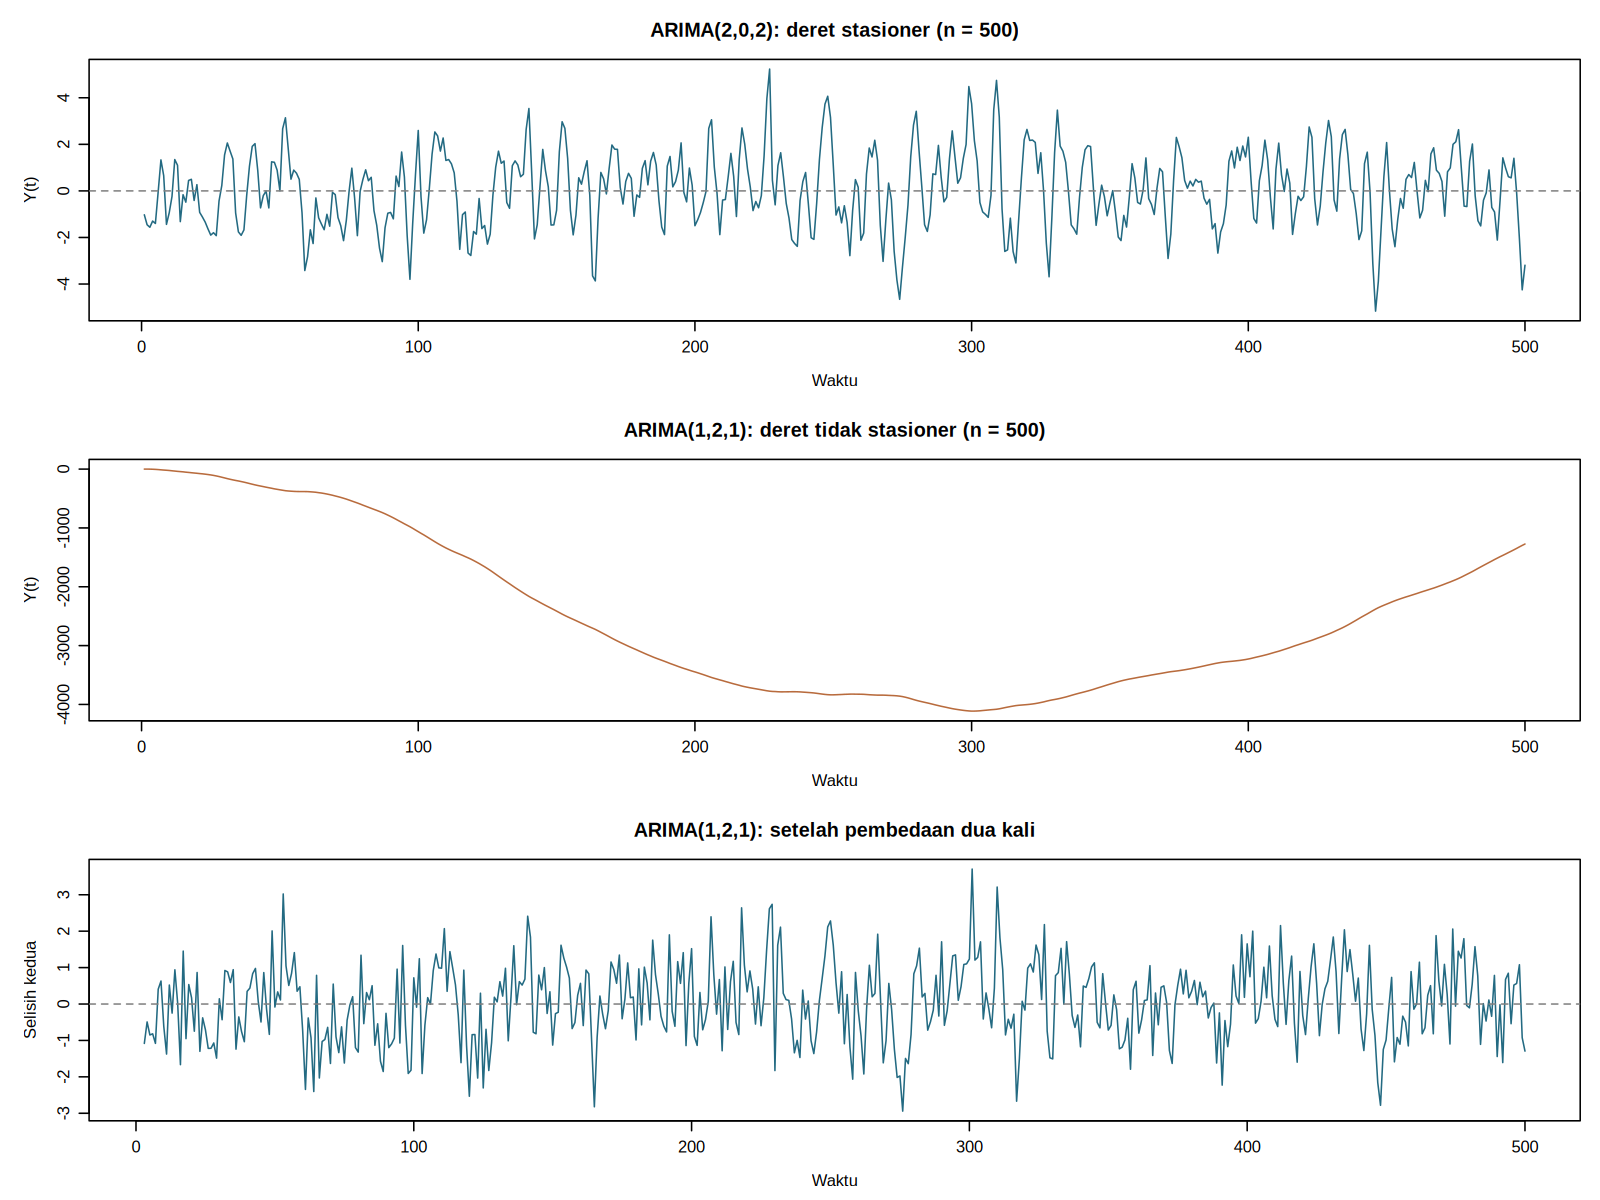

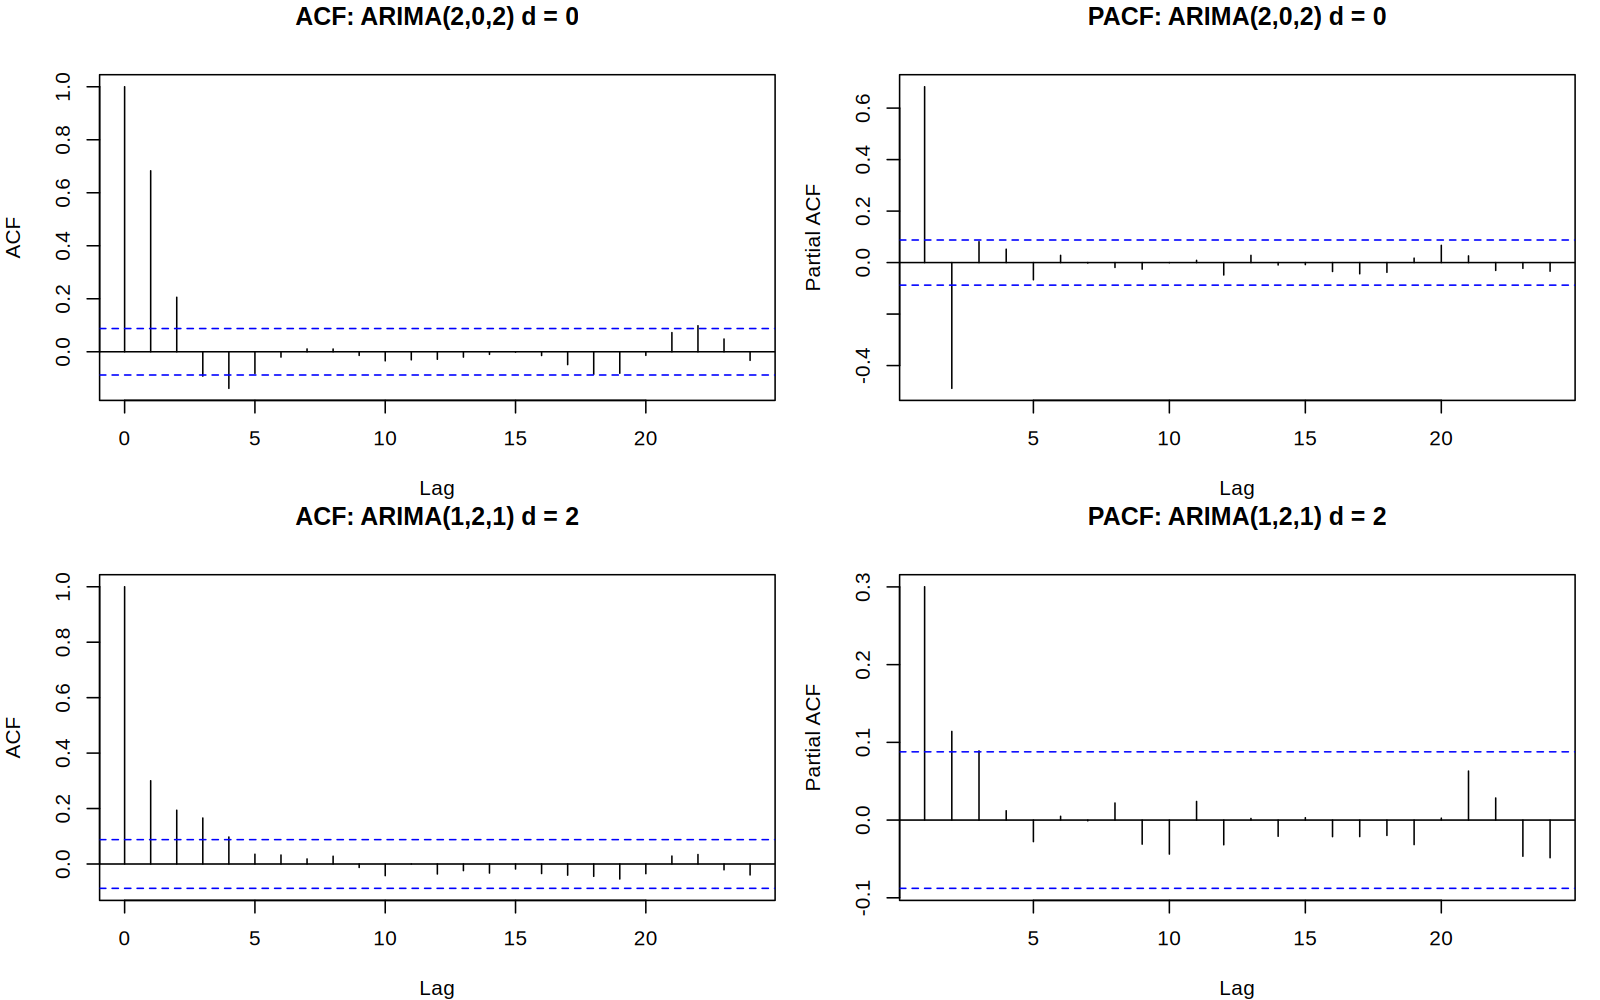

In [7]:
from IPython.display import Image, display
display(Image(filename="hasil_kelompok9_final/01_deret.png", width=1100))
display(Image(filename="hasil_kelompok9_final/02_acf_pacf.png", width=1100))

### Interpretasi grafik
ARIMA(2,0,2) berfluktuasi di sekitar nol tanpa tren jangka panjang yang jelas. Pada realisasi ARIMA(1,2,1), level turun hingga sekitar waktu ke-300 lalu meningkat kembali. Setelah pembedaan dua kali, fluktuasi kembali berada di sekitar nol. Sifat stasioneritas didasarkan pada model pembangkit dan pemeriksaan akar, bukan semata-mata bentuk grafik.

ACF model pertama menunjukkan korelasi positif pada lag awal, diikuti nilai negatif pada beberapa lag berikutnya dan kemudian melemah. Pada model kedua setelah pembedaan dua kali, autokorelasi positif lag awal cenderung menurun. ACF dan PACF model ARMA umumnya meluruh, sehingga tidak digunakan aturan cut-off AR murni atau MA murni untuk menyatakan orde secara pasti.

## 5. Nomor 2 — simulasi 30 ulangan
Parameter dan panjang deret tetap. Seed 12345–12374 mengubah realisasi acak antarulangan. Jadwal seed yang sama diterapkan pada kedua model, tetapi perbandingan CSS–MLE dilakukan secara terpisah di dalam setiap model.

Ada 2 model × 30 ulangan × 2 metode = **120 pendugaan model**. Karena model pertama memiliki 4 koefisien dan model kedua 2 koefisien, jumlah baris estimasi adalah 30 × 2 × (4+2) = **360 baris**.

In [8]:
%%R
records <- list(); k <- 0L
for(id in names(models)) {
 for(b in seq_len(B)) {
  # Seed 12345--12374; berbeda antarulangan, tidak memakai seed NIM.
  # Jadwal seed yang sama diterapkan pada kedua model; analisis dilakukan per model.
  set.seed(BASE_SEED+b-1L)
  y <- simulate(models[[id]])
  k <- k+1L
  records[[k]] <- fit_pair(y,models[[id]],id,b)
 }
}
sim <- do.call(rbind,records); rownames(sim) <- NULL
checks <- unique(sim[,c('Model','Ulangan','Metode','Kode','Percobaan','Peringatan')])
counts <- aggregate(Dugaan~Model+Parameter+Metode,sim,length)
names(counts)[4] <- 'Jumlah'
stopifnot(nrow(sim)==360L,nrow(checks)==120L,all(checks$Kode==0),all(counts$Jumlah==B))
cat('Jumlah baris parameter:',nrow(sim),'\n')
cat('Jumlah pendugaan model:',nrow(checks),'\n')
cat('Semua kode konvergensi nol:',all(checks$Kode==0),'\n')
cat('Pendugaan yang memerlukan percobaan kedua:',sum(checks$Percobaan>1),'\n')
cat('Pendugaan dengan catatan peringatan:',sum(nzchar(checks$Peringatan)),'\n\n')
print(counts,row.names=FALSE)
if(any(nzchar(checks$Peringatan))) print(subset(checks,nzchar(Peringatan)),row.names=FALSE)
write.table(sim,file.path(out,'estimasi_30_ulangan.tsv'),sep='\t',row.names=FALSE)
write.table(checks,file.path(out,'audit_konvergensi.tsv'),sep='\t',row.names=FALSE)

Jumlah baris parameter: 360 
Jumlah pendugaan model: 120 
Semua kode konvergensi nol: TRUE 
Pendugaan yang memerlukan percobaan kedua: 0 
Pendugaan dengan catatan peringatan: 0 

        Model Parameter Metode Jumlah
 ARIMA(1,2,1)      phi1    CSS     30
 ARIMA(2,0,2)      phi1    CSS     30
 ARIMA(2,0,2)      phi2    CSS     30
 ARIMA(1,2,1)    theta1    CSS     30
 ARIMA(2,0,2)    theta1    CSS     30
 ARIMA(2,0,2)    theta2    CSS     30
 ARIMA(1,2,1)      phi1     ML     30
 ARIMA(2,0,2)      phi1     ML     30
 ARIMA(2,0,2)      phi2     ML     30
 ARIMA(1,2,1)    theta1     ML     30
 ARIMA(2,0,2)    theta1     ML     30
 ARIMA(2,0,2)    theta2     ML     30


**Hasil pemeriksaan:** seluruh 120 pendugaan konvergen dengan kode 0, tanpa peringatan dan tanpa memerlukan percobaan kedua. Setiap kombinasi model–metode–parameter mempunyai tepat 30 estimasi. Seluruh ulangan digunakan dalam ringkasan berikut.

## 6. Bias, ragam, dan RMSE
Untuk parameter sebenarnya $\beta$ dan $R=30$ ulangan:
$$\overline{\hat\beta}=\frac{1}{R}\sum_{r=1}^R\hat\beta_r,$$
$$\widehat{\mathrm{Bias}}=\overline{\hat\beta}-\beta,$$
$$s^2=\frac{1}{R-1}\sum_{r=1}^R(\hat\beta_r-\overline{\hat\beta})^2,$$
$$\widehat{\mathrm{MSE}}=\frac{1}{R}\sum_{r=1}^R(\hat\beta_r-\beta)^2,\qquad \mathrm{RMSE}=\sqrt{\widehat{\mathrm{MSE}}}.$$

Bias absolut kecil menunjukkan kedekatan rata-rata estimasi dengan parameter sebenarnya. Ragam kecil menunjukkan kestabilan antarulangan. RMSE merupakan ukuran tambahan yang menggabungkan bias dan penyebaran.

Karena ragam di atas memakai penyebut $R-1$, hubungan yang benar adalah
$$\widehat{\mathrm{MSE}}=\frac{R-1}{R}s^2+\widehat{\mathrm{Bias}}^2.$$
Sel berikut memeriksa identitas tersebut secara numerik.

In [9]:
%%R
summary <- do.call(rbind,lapply(split(sim,interaction(sim$Model,sim$Parameter,sim$Metode,drop=TRUE)),function(z) {
 data.frame(Model=z$Model[1],Parameter=z$Parameter[1],Metode=z$Metode[1],
 Benar=z$Benar[1],Jumlah=nrow(z),Rata_rata=mean(z$Dugaan),Bias=mean(z$Galat),
 Ragam=var(z$Dugaan),MSE=mean(z$Galat^2),RMSE=sqrt(mean(z$Galat^2)))
}))
summary <- summary[order(summary$Model,summary$Parameter,summary$Metode),];rownames(summary)<-NULL
stopifnot(all(abs(summary$MSE-((B-1)/B*summary$Ragam+summary$Bias^2))<1e-10))
print(summary,digits=6,row.names=FALSE)
comparison <- merge(subset(summary,Metode=='CSS'),subset(summary,Metode=='ML'),
 by=c('Model','Parameter'),suffixes=c('_CSS','_MLE'))
choose <- function(a,b) ifelse(a<b,'CSS',ifelse(a>b,'MLE','Sama'))
comparison$Bias_lebih_kecil <- choose(abs(comparison$Bias_CSS),abs(comparison$Bias_MLE))
comparison$Ragam_lebih_kecil <- choose(comparison$Ragam_CSS,comparison$Ragam_MLE)
comparison$RMSE_lebih_kecil <- choose(comparison$RMSE_CSS,comparison$RMSE_MLE)
print(comparison[,c('Model','Parameter','Bias_lebih_kecil','Ragam_lebih_kecil','RMSE_lebih_kecil')],row.names=FALSE)
write.table(summary,file.path(out,'ringkasan.tsv'),sep='\t',row.names=FALSE)
write.table(comparison,file.path(out,'perbandingan.tsv'),sep='\t',row.names=FALSE)

        Model Parameter Metode Benar Jumlah Rata_rata         Bias      Ragam
 ARIMA(1,2,1)      phi1    CSS   0.7     30  0.695056 -0.004944236 0.00490600
 ARIMA(1,2,1)      phi1     ML   0.7     30  0.699543 -0.000457434 0.00471957
 ARIMA(1,2,1)    theta1    CSS  -0.4     30 -0.406629 -0.006628604 0.00872065
 ARIMA(1,2,1)    theta1     ML  -0.4     30 -0.411765 -0.011764702 0.00883735
 ARIMA(2,0,2)      phi1    CSS   0.6     30  0.606854  0.006853815 0.01883985
 ARIMA(2,0,2)      phi1     ML   0.6     30  0.593655 -0.006344973 0.01725585
 ARIMA(2,0,2)      phi2    CSS  -0.3     30 -0.310208 -0.010208006 0.00515753
 ARIMA(2,0,2)      phi2     ML  -0.3     30 -0.304049 -0.004049142 0.00523689
 ARIMA(2,0,2)    theta1    CSS   0.5     30  0.481331 -0.018668553 0.01816255
 ARIMA(2,0,2)    theta1     ML   0.5     30  0.493856 -0.006143804 0.01577479
 ARIMA(2,0,2)    theta2    CSS   0.3     30  0.298336 -0.001664456 0.00768775
 ARIMA(2,0,2)    theta2     ML   0.3     30  0.305885  0.0058851

### Ringkasan perbandingan berdampingan

| Model | Parameter | Bias CSS | Bias MLE | Ragam CSS | Ragam MLE |
| --- | --- | --- | --- | --- | --- |
| ARIMA(1,2,1) | phi1 | -0.004944 | -0.000457 | 0.004906 | 0.004720 |
| ARIMA(1,2,1) | theta1 | -0.006629 | -0.011765 | 0.008721 | 0.008837 |
| ARIMA(2,0,2) | phi1 | 0.006854 | -0.006345 | 0.018840 | 0.017256 |
| ARIMA(2,0,2) | phi2 | -0.010208 | -0.004049 | 0.005158 | 0.005237 |
| ARIMA(2,0,2) | theta1 | -0.018669 | -0.006144 | 0.018163 | 0.015775 |
| ARIMA(2,0,2) | theta2 | -0.001664 | 0.005885 | 0.007688 | 0.006035 |

### Interpretasi bias dan ragam
**ARIMA(2,0,2).** MLE memiliki bias absolut lebih kecil untuk φ₁, φ₂, dan θ₁; CSS memiliki bias absolut lebih kecil untuk θ₂. Dari sisi ragam, MLE lebih kecil untuk φ₁, θ₁, dan θ₂, sedangkan CSS sedikit lebih kecil untuk φ₂. Sebagai contoh, ragam φ₁ adalah 0,018840 (CSS) dan 0,017256 (MLE). Untuk φ₂, ragam CSS 0,005158 sedikit lebih kecil daripada MLE 0,005237. Walaupun demikian, RMSE MLE lebih kecil pada seluruh parameter model ini; selisih RMSE φ₂ sangat kecil.

**ARIMA(1,2,1).** MLE memiliki bias absolut, ragam, dan RMSE lebih kecil untuk φ₁. Sebaliknya, CSS memiliki ketiga ukuran yang lebih kecil untuk θ₁. Ragam φ₁ adalah 0,004906 (CSS) dan 0,004720 (MLE), sedangkan ragam θ₁ adalah 0,008721 (CSS) dan 0,008837 (MLE). Dengan demikian, tidak ada satu metode yang unggul untuk kedua parameter model ini.

## 7. Boxplot dan diagram batang
Baris atas boxplot menunjukkan **30 estimasi**; baris bawah menunjukkan **30 galat**. Garis merah putus-putus adalah nilai parameter sebenarnya pada baris atas dan nol pada baris bawah. Titik merah menunjukkan **rata-rata**, sedangkan garis hitam tebal di dalam kotak menunjukkan **median**.

Bias adalah selisih **rata-rata estimasi** terhadap nilai sebenarnya. Tinggi kotak adalah **IQR**, bukan ragam. Nilai ragam dibaca dari tabel; grafik digunakan untuk melihat bentuk sebaran dan pencilan. Diagram batang melengkapi boxplot dengan nilai bias dan ragam yang telah dihitung.

In [10]:
%%R
cols <- c('#F0BB72','#75AEC2')
for(id in names(models)) {
 pars <- names(true_coef(models[[id]]))
 tag <- if(id=='ARIMA(2,0,2)') '202' else '121'
 png(file.path(out,paste0('03_boxplot_',tag,'.png')),width=1600,height=1000,res=150)
 par(mfrow=c(2,length(pars)),mar=c(4,4.2,3,1),oma=c(0,0,3,0),mgp=c(2.5,0.8,0))
 for(value in c('Dugaan','Galat')) for(p in pars) {
  z <- subset(sim,Model==id & Parameter==p)
  vals <- list(CSS=z[z$Metode=='CSS',value],MLE=z[z$Metode=='ML',value])
  boxplot(vals,col=cols,main=p,ylab=value,xlab='Metode')
  abline(h=if(value=='Dugaan') z$Benar[1] else 0,lty=2,col='#B02030')
  points(1:2,sapply(vals,mean),pch=18,col='#B02030',cex=1.1)
 }
 mtext(paste(id,'| 30 ulangan | titik merah = rata-rata'),outer=TRUE,cex=1.15)
 dev.off()
}
png(file.path(out,'04_bias_ragam.png'),width=1600,height=1000,res=150)
par(mfrow=c(2,2),mar=c(4,4.5,3,1))
for(id in names(models)) for(metric in c('Bias','Ragam')) {
 z <- subset(summary,Model==id);pars <- names(true_coef(models[[id]]))
 vals <- rbind(CSS=z[z$Metode=='CSS',metric][match(pars,z$Parameter[z$Metode=='CSS'])],
 MLE=z[z$Metode=='ML',metric][match(pars,z$Parameter[z$Metode=='ML'])])
 colnames(vals) <- pars
 limits <- range(c(0,vals)); span <- diff(limits)
 barplot(vals,beside=TRUE,col=cols,main=paste(id,metric),ylab=metric,
 ylim=c(limits[1]-0.05*span,limits[2]+0.3*span),
 legend.text=TRUE,args.legend=list(x='topright',bty='n',cex=.8))
 abline(h=0,col='gray40')
}
dev.off()
capture.output(sessionInfo(),file=file.path(out,'sessionInfo.txt'))

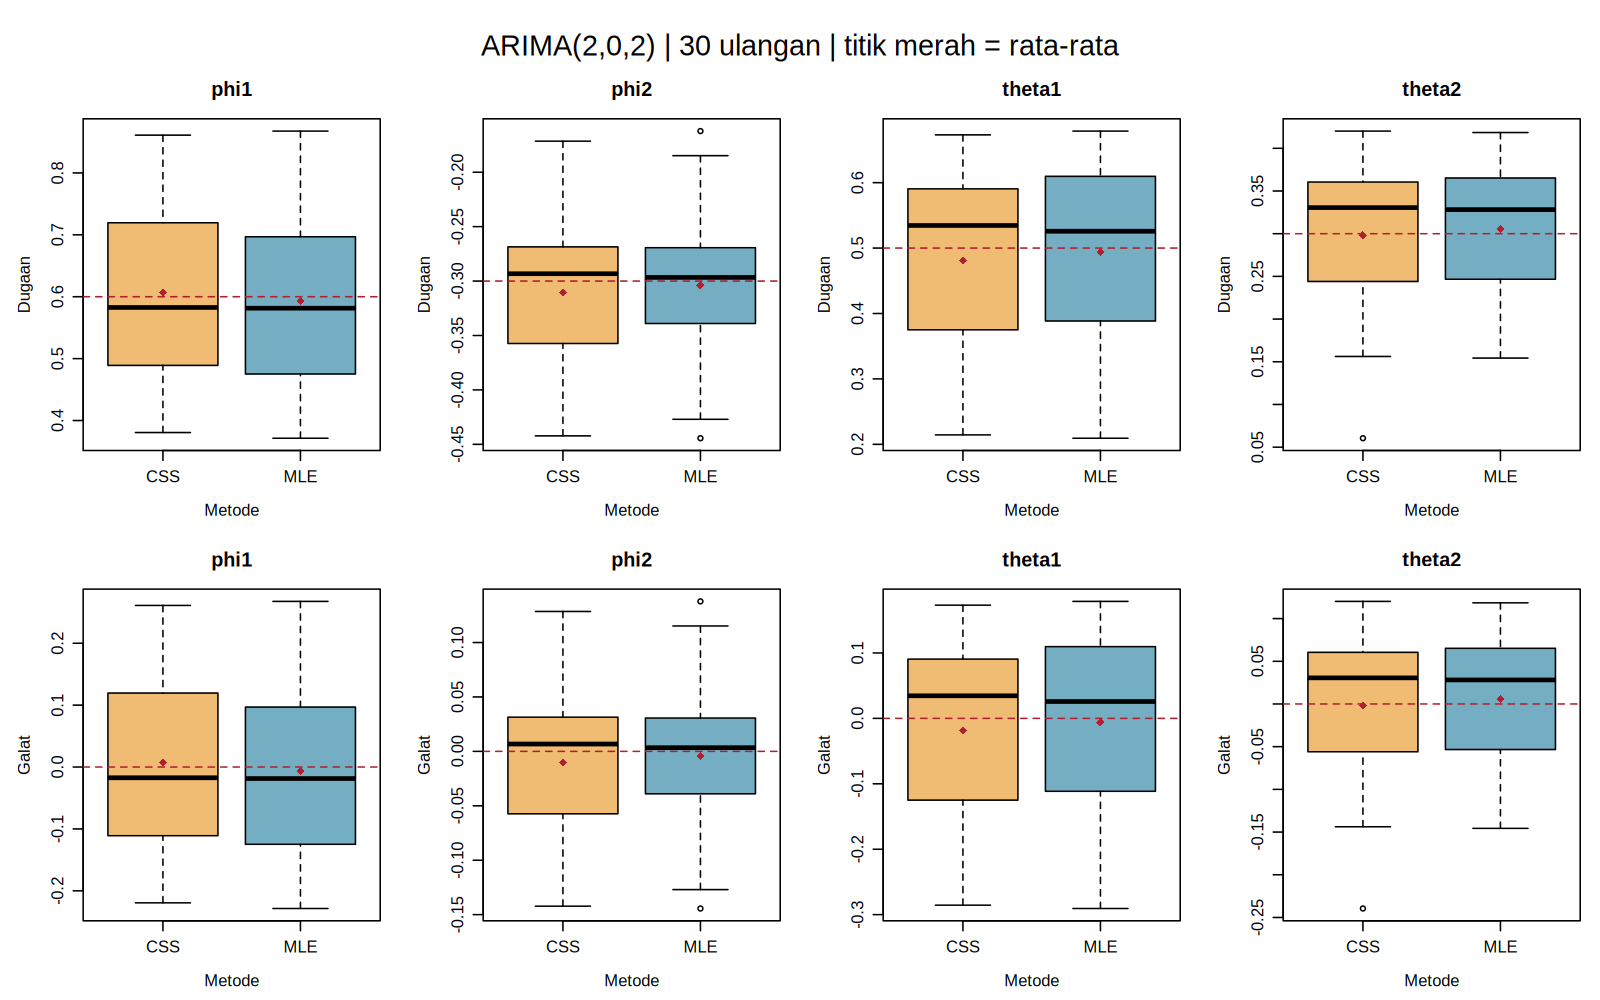

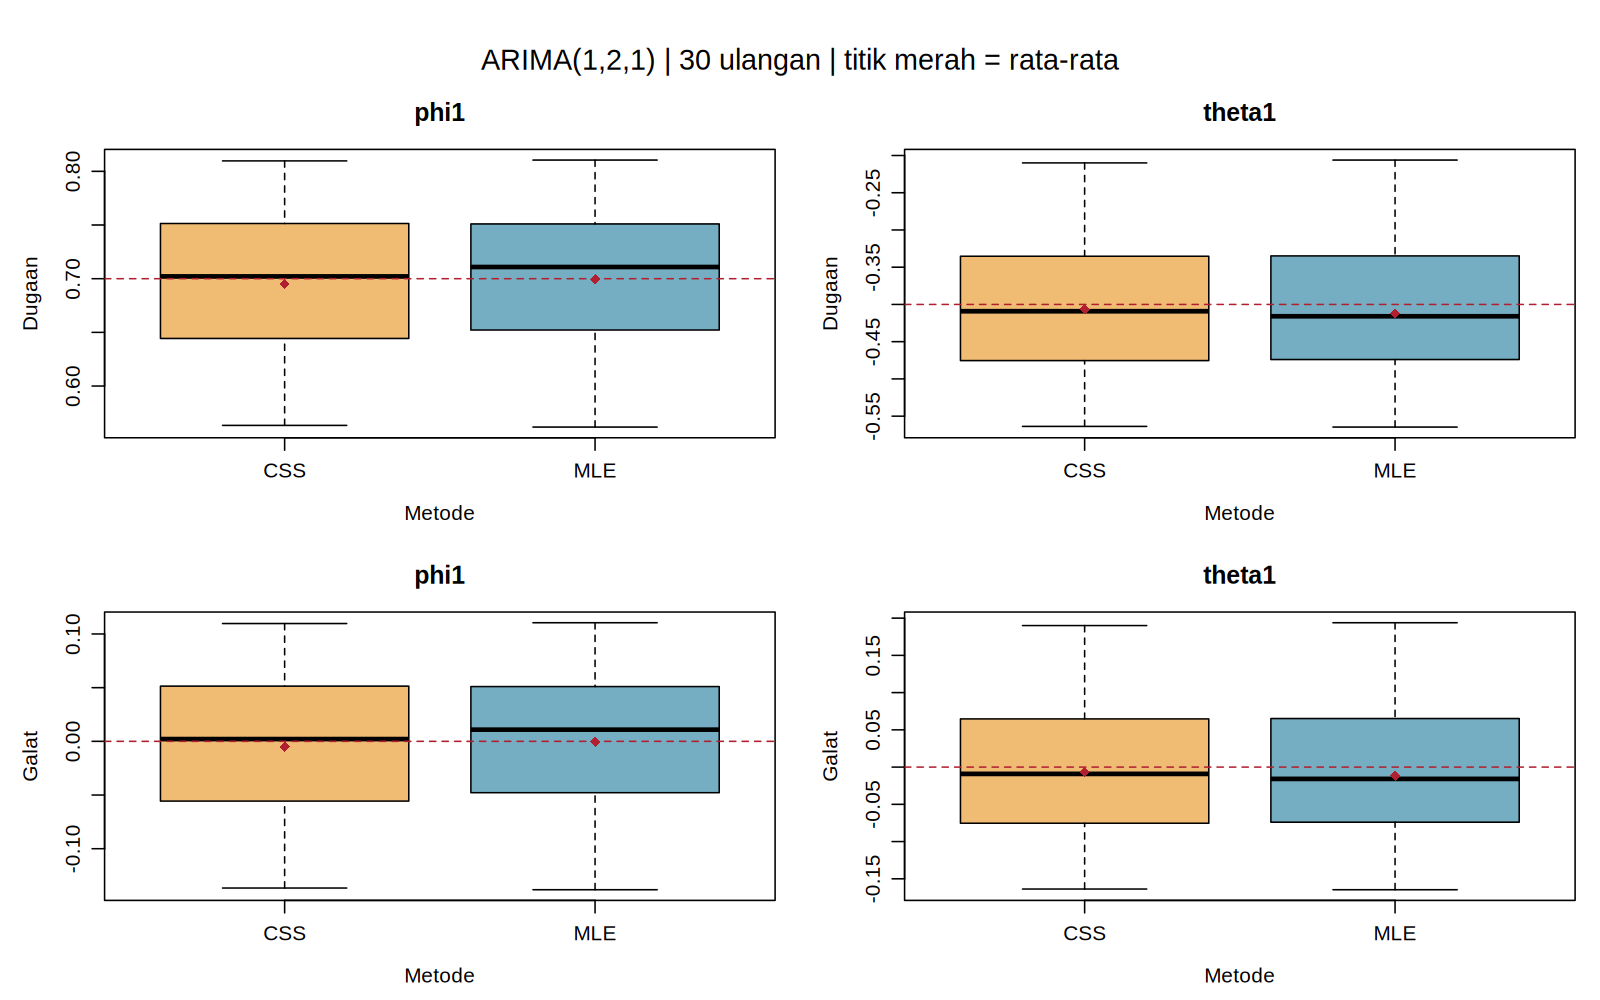

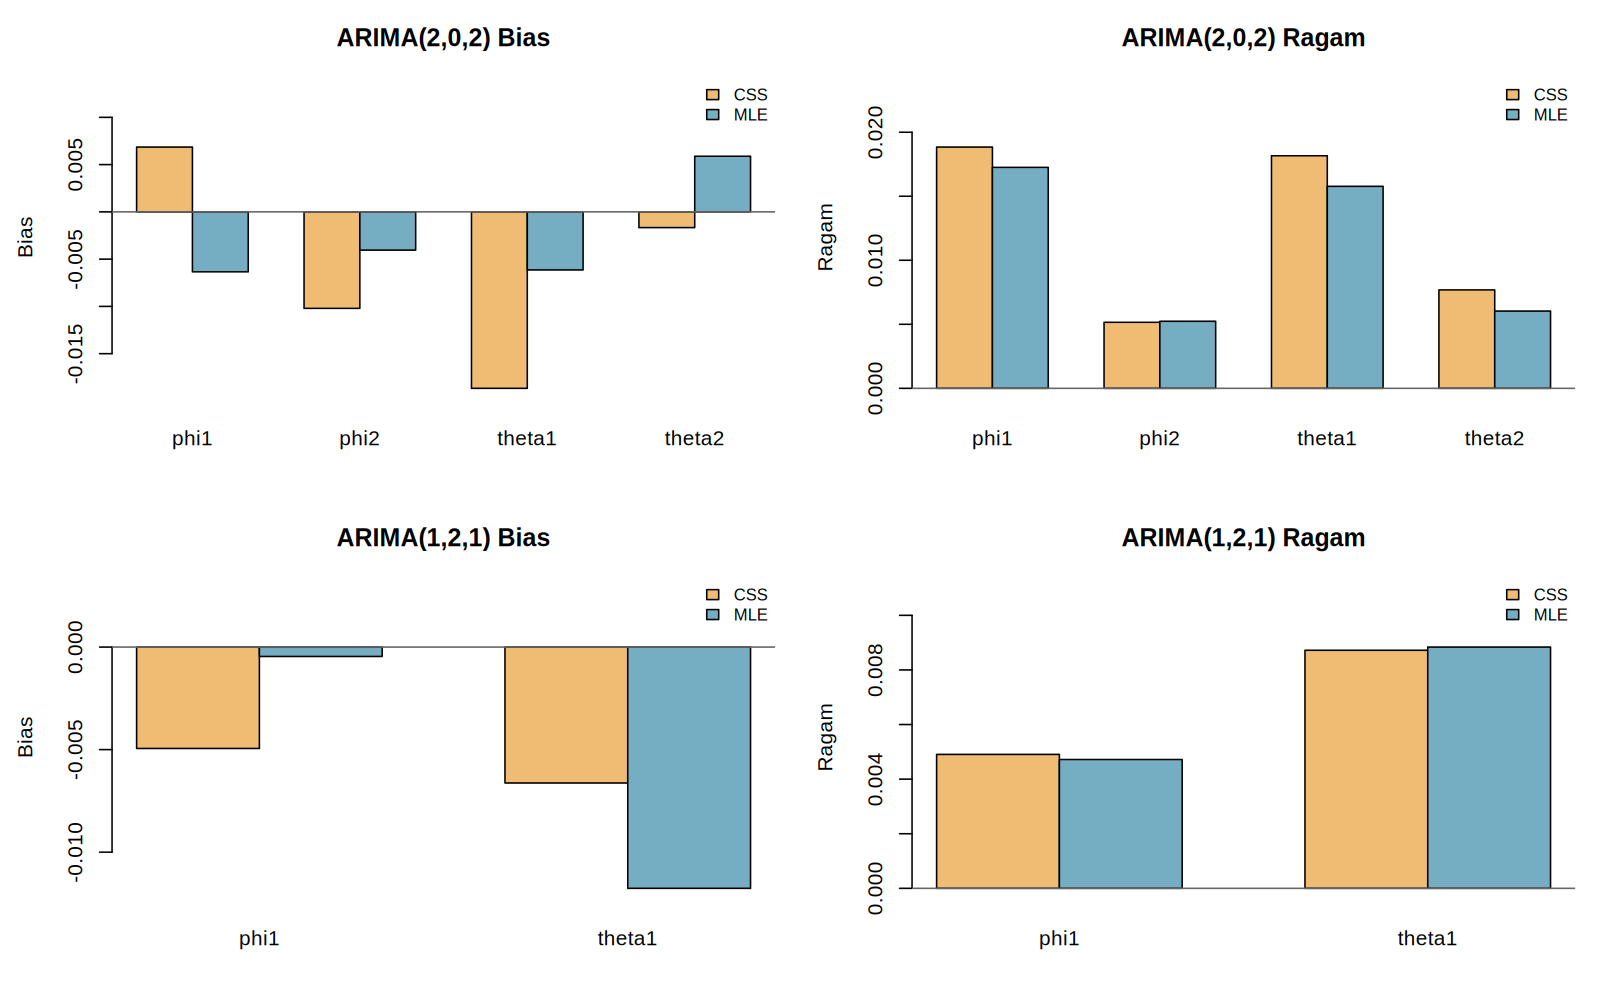

In [11]:
from IPython.display import Image, display
display(Image(filename="hasil_kelompok9_final/03_boxplot_202.png", width=1100))
display(Image(filename="hasil_kelompok9_final/03_boxplot_121.png", width=1100))
display(Image(filename="hasil_kelompok9_final/04_bias_ragam.png", width=1100))

### Interpretasi boxplot
Pada ARIMA(2,0,2), sebaran kedua metode banyak bertumpang tindih. Rata-rata estimasi umumnya berada dekat nilai sebenarnya, tetapi tetap ada bias yang terlihat pada posisi titik merah. Terdapat pencilan pada θ₂ untuk CSS dan pada φ₂ untuk MLE menurut aturan whisker boxplot. Semua pencilan tetap dipertahankan dalam perhitungan. Lebar IQR saja tidak selalu memberikan urutan yang sama dengan ragam karena ragam juga dipengaruhi pengamatan jauh dari rata-rata.

Pada ARIMA(1,2,1), kotak CSS dan MLE tampak hampir sama. Rata-rata galat φ₁ pada MLE lebih dekat nol daripada CSS; untuk θ₁, rata-rata galat CSS lebih dekat nol. Perbedaan ragam kedua metode kecil dan tidak terlihat mencolok secara visual.

Diagram batang memperjelas bahwa arah bias dan besar ragam tidak selalu menguntungkan metode yang sama. Perbandingan dilakukan untuk masing-masing parameter, bukan dengan menyimpulkan pemenang hanya dari tinggi satu kotak.

## 8. Ringkasan metode dengan ukuran lebih kecil

| Model | Parameter | Bias absolut | Ragam | RMSE |
| --- | --- | --- | --- | --- |
| ARIMA(1,2,1) | phi1 | MLE | MLE | MLE |
| ARIMA(1,2,1) | theta1 | CSS | CSS | CSS |
| ARIMA(2,0,2) | phi1 | MLE | MLE | MLE |
| ARIMA(2,0,2) | phi2 | MLE | CSS | MLE |
| ARIMA(2,0,2) | theta1 | MLE | MLE | MLE |
| ARIMA(2,0,2) | theta2 | CSS | MLE | MLE |

## 9. Kesimpulan
Berdasarkan simulasi dengan panjang deret 500 pengamatan dan 30 ulangan:

1. **ARIMA(2,0,2):** MLE cenderung lebih baik pada skenario ini. MLE memiliki bias absolut lebih kecil pada tiga dari empat parameter, ragam lebih kecil pada tiga dari empat parameter, dan RMSE lebih kecil pada seluruh parameter. CSS tetap memiliki kelebihan pada bias absolut θ₂ dan ragam φ₂.
2. **ARIMA(1,2,1):** hasil bergantung pada parameter. MLE lebih baik untuk φ₁, sedangkan CSS lebih baik untuk θ₁ berdasarkan bias absolut, ragam, dan RMSE.
3. Seluruh pendugaan konvergen, sehingga ringkasan menggunakan 30 ulangan lengkap per kombinasi model, metode, dan parameter.

Hasil ini menunjukkan **kestabilan empiris antarulangan**, bukan bukti konsistensi asimtotik. Konsistensi secara statistik memerlukan kajian ketika ukuran sampel bertambah. Perbedaan yang kecil pada 30 ulangan juga belum merupakan bukti bahwa salah satu metode unggul secara signifikan atau berlaku untuk semua parameter dan ukuran sampel.

Kesimpulan ini mengikuti hasil R pada pengaturan yang tercantum. Jika parameter, seed, n, atau metode diubah, jalankan seluruh kode dan perbarui pembahasan sesuai hasil terbaru.